# NLP PR 1: Airline Tweet Sentiment Analyzer

From raw tweets to a deployed Streamlit app. Dataset: Twitter US Airline Sentiment (Kaggle, `Tweets.csv`).

## Task 1: NLP Fundamentals, Pipeline & Data Exploration
**Objective:** understand what NLP is, see the pipeline, and explore the airline tweets.
**Expected output:** explanations, tables, EDA plots and real tweets showing NLP challenges.

### 1.1 What is NLP and why we need it
Natural Language Processing (NLP) is the part of AI that lets computers read, understand and work with human language. Text is unstructured, so a computer cannot use it directly like a table of numbers. Humans create a huge amount of text every day (tweets, reviews, emails, news), and nobody can read all of it manually. NLP turns this text into something a program can measure and act on.

Five real applications:
1. **Search engines** - match a query with the right pages (Google search in Hindi and Gujarati).
2. **Spam filtering** - Gmail separates spam from real mail.
3. **Chatbots** - bank and railway bots (for example IRCTC's AskDISHA) answer customer questions.
4. **Machine translation** - Google Translate and Bhashini translate between Indian languages.
5. **Customer-review analysis** - e-commerce sites such as Flipkart and Amazon India find out what customers like or dislike.

### 1.2 Common NLP tasks and approaches
| NLP task | One-line description | Example |
|---|---|---|
| Text classification | Give one label to a whole text | Mail -> spam / not spam |
| Sentiment analysis | Find the opinion in a text | "Great service" -> positive |
| Named-entity recognition | Find names, places, dates | "Air India flew to Delhi" -> Air India (ORG), Delhi (PLACE) |
| POS tagging | Label each word with its grammar role | "flight" -> noun |
| Machine translation | Translate between languages | English -> Hindi |
| Summarisation | Shorten a long text | News article -> 2 lines |
| Question answering | Answer a question from text | "Who is the PM?" -> name |

| Approach family | Idea | Used in this practical |
|---|---|---|
| Heuristic (rules) | Hand-written rules and word lists | Own airline lexicon |
| API-based | Send text to a ready-made service | NLTK VADER |
| Machine-Learning-based | Learn from labelled data | BoW / N-grams / TF-IDF / Word2Vec |

### 1.3 The NLP pipeline
```
Data collection -> Text cleaning -> Tokenisation -> Stop-word handling -> Feature extraction -> Model training -> Evaluation -> Deployment
```
| Stage | What I do on the airline tweets | Task |
|---|---|---|
| Data collection | Load `Tweets.csv` from Kaggle | Task 1 |
| Text cleaning | RegEx removes URLs, mentions, symbols | Task 2 |
| Tokenisation | Split the cleaned text into words | Task 2 |
| Stop-word handling | Remove common words but keep negations | Task 2 |
| Feature extraction | BoW, TF-IDF, N-grams, Word2Vec | Tasks 4, 5 |
| Model training | Logistic Regression, Naive Bayes | Task 6 |
| Evaluation | Accuracy, macro-F1, confusion matrix | Tasks 3, 6 |
| Deployment | Streamlit app | Task 8 |

### 1.4 Load and inspect

In [1]:
import pandas as pd
import numpy as np

np.random.seed(42)
df = pd.read_csv('dataset/Tweets.csv')
print(df.shape)

(14640, 15)


In [2]:
df = df[['text', 'airline_sentiment', 'airline']]
df.head()

,text,airline_sentiment,airline
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America
1,@VirginAmerica plus you've added commercials t...,positive,Virgin America
2,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
3,@VirginAmerica it's really aggressive to blast...,negative,Virgin America
4,@VirginAmerica and it's a really big bad thing...,negative,Virgin America


In [3]:
print(df.isnull().sum())
print('Duplicate tweets:', df.duplicated().sum())

text                 0
airline_sentiment    0
airline              0
dtype: int64
Duplicate tweets: 188


In [4]:
df = df.drop_duplicates().reset_index(drop=True)
print('Shape after dropping duplicates:', df.shape)

Shape after dropping duplicates: (14452, 3)


In [5]:
for t in df['text'].sample(5, random_state=42):
    print(t)
    print('-' * 40)

@united Surprised to go from 1K last year to nothing this year. What happened to the "soft landing" policy of no more than 1 level?
----------------------------------------
@AmericanAir @sa_craig no, not helped one bit. actually ended up driving home due to extreme disorganization and lack of communication.
----------------------------------------
@AmericanAir yes we did make it home. But by no means am I happy. I've always chosen AA as my 1st choice when flying, I'm rethinking that...
----------------------------------------
“@JetBlue: Our fleet's on fleek. http://t.co/g12sn5qsqZ”- no... Yall better than this
----------------------------------------
@AmericanAir Thanks! Great stuff! I can only imagine how jammed everything is.
----------------------------------------


### 1.5 EDA plots

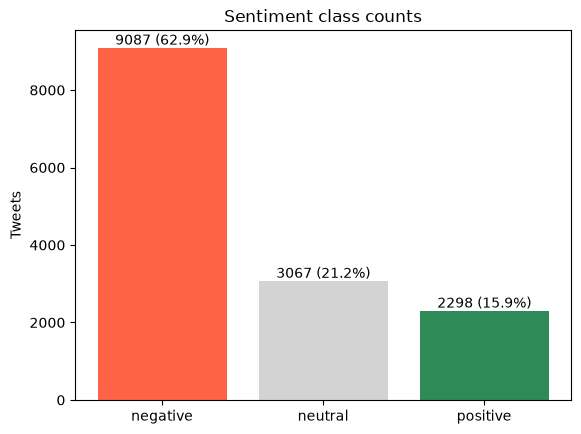

In [6]:
import matplotlib.pyplot as plt

counts = df['airline_sentiment'].value_counts()
percent = counts / counts.sum() * 100

plt.bar(counts.index, counts.values, color=['tomato', 'lightgrey', 'seagreen'])
for i, (c, p) in enumerate(zip(counts.values, percent.values)):
    plt.text(i, c, f'{c} ({p:.1f}%)', ha='center', va='bottom')
plt.title('Sentiment class counts')
plt.ylabel('Tweets')
plt.show()

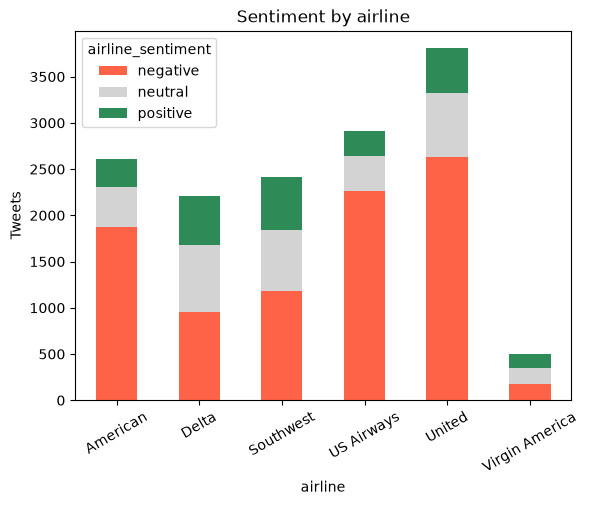

In [7]:
pd.crosstab(df['airline'], df['airline_sentiment']).plot(kind='bar', stacked=True, color=['tomato', 'lightgrey', 'seagreen'])
plt.title('Sentiment by airline')
plt.ylabel('Tweets')
plt.xticks(rotation=30)
plt.show()

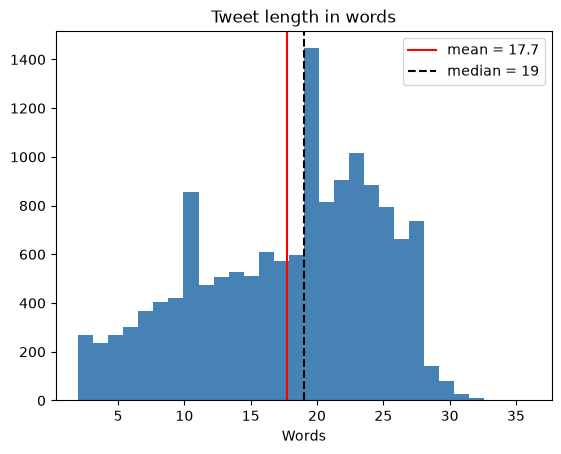

In [8]:
df['word_count'] = df['text'].str.split().str.len()

plt.hist(df['word_count'], bins=30, color='steelblue')
plt.axvline(df['word_count'].mean(), color='red', label=f"mean = {df['word_count'].mean():.1f}")
plt.axvline(df['word_count'].median(), color='black', linestyle='--', label=f"median = {df['word_count'].median():.0f}")
plt.title('Tweet length in words')
plt.xlabel('Words')
plt.legend()
plt.show()

**Interpretation:** the classes are imbalanced, with negative tweets the clear majority. A model that always says "negative" would already get a high accuracy, so accuracy alone is misleading. I will use **macro-F1** (average of the F1 of each class) as the main metric. Most tweets are short, so each tweet has very little text to work with.

### 1.6 Challenges in NLP: evidence from real tweets

In [9]:
challenge_patterns = {
    'Negation': r"\b(?:not|never|no)\b",
    'Sarcasm / irony': r"oh great|yeah right|thanks for nothing|love how|great job",
    'Slang / misspelling': r"\b(?:omg|lol|plz|pls|thx|ur|u|wtf)\b",
    'Emoji / special symbols': r"[^\x00-\x7F]",
    'Hard to label': r"(?=.*\b(?:thanks|thank|great)\b)(?=.*\b(?:but|delayed|late|cancelled)\b)",
}

In [10]:
why = {
    'Negation': 'A word like "happy" looks positive, but "not" reverses it.',
    'Sarcasm / irony': 'The words are positive but the meaning is a complaint.',
    'Slang / misspelling': 'Informal spelling is not in normal dictionaries.',
    'Emoji / special symbols': 'Symbols carry emotion but normal word rules ignore them.',
    'Hard to label': 'Praise and complaint are mixed, so even humans may disagree.',
}

rows = []
for name, pattern in challenge_patterns.items():
    found = df[df['text'].str.contains(pattern, case=False, regex=True)]
    if len(found) > 0:
        row = found.sample(1, random_state=42).iloc[0]
        rows.append([name, row['text'], row['airline_sentiment'], why[name]])

pd.set_option('display.max_colwidth', None)
pd.DataFrame(rows, columns=['Challenge', 'Real tweet', 'Label', 'Why it is hard'])

,Challenge,Real tweet,Label,Why it is hard
0,Negation,@AmericanAir What's with your baggage handlers calling out at DFW today? No luggage onboard the planes.,negative,"A word like ""happy"" looks positive, but ""not"" reverses it."
1,Sarcasm / irony,@USAirways You guys are screwing up my trip. Thanks for nothing. #lazy,negative,The words are positive but the meaning is a complaint.
2,Slang / misspelling,"@USAirways any chance u can help our family rebook their flight that was Cancelled Flightled, #4487?",negative,Informal spelling is not in normal dictionaries.
3,Emoji / special symbols,“@USAirways: @TMadCLE We don't like to hear this. We're sorry that it's taking so long to get through.” Stop sending generic responses,negative,Symbols carry emotion but normal word rules ignore them.
4,Hard to label,@JetBlue thanks for the update. 'Preciate it. Hope it gets here. Been delayed 2 days getting back,negative,"Praise and complaint are mixed, so even humans may disagree."


## Task 2: Text Cleaning with RegEx & Tokenisation
**Objective:** turn noisy tweets into clean, tokenised text.
**Expected output:** a tested `clean_text()` function, a `clean_text` column, tokens and vocabulary statistics.

### 2.1 Cleaning rules
| Rule | Why | Possible loss |
|---|---|---|
| Lowercase | "Delay" and "delay" become one word | Capital letters for anger ("TERRIBLE") are lost |
| Remove URLs | Links carry no sentiment | None |
| Remove @mentions | Every tweet starts with an airline name, which is not sentiment | Airline name is lost (kept in the `airline` column) |
| Hashtag: keep word, drop `#` | `#delayed` is a useful word | None |
| Remove apostrophes | `don't` becomes `dont`, one negation word | None |
| Remove numbers and punctuation | Reduces noise | "!!!" and emojis can carry sentiment |
| Collapse extra spaces | Clean tokens | None |

### 2.2 RegEx practice

In [11]:
import re

sample = "@United my flight #delayed AGAIN!!! Check https://t.co/abc123 now, I paid $250   :( "
print(sample)

@United my flight #delayed AGAIN!!! Check https://t.co/abc123 now, I paid $250   :( 


In [12]:
print(re.findall(r'https?://\S+', sample))
print(re.findall(r'@\w+', sample))
print(re.sub(r'https?://\S+', ' ', sample))

['https://t.co/abc123']
['@United']
@United my flight #delayed AGAIN!!! Check   now, I paid $250   :( 


In [13]:
print(re.sub(r'#(\w+)', r'\1', sample))
print(re.findall(r'\d+', sample))

@United my flight delayed AGAIN!!! Check https://t.co/abc123 now, I paid $250   :( 
['123', '250']


In [14]:
lower = sample.lower()
print(re.sub(r'[^a-z\s]', ' ', lower))
print(re.sub(r'\s+', ' ', 'too     many   spaces'))

 united my flight  delayed again    check https   t co abc    now  i paid           
too many spaces


| Pattern | Meaning of each symbol | Example match |
|---|---|---|
| `https?://\S+` | `http`, optional `s`, `://`, then `\S+` = one or more non-space characters | `https://t.co/abc123` |
| `@\w+` | `@` then `\w+` = one or more letters, digits or `_` | `@united` |
| `#(\w+)` | `#` then a group `( )` that captures the word | `#delayed` -> `delayed` |
| `\d+` | one or more digits | `250` |
| `[^a-z\s]` | `^` inside `[ ]` means NOT; any character that is not a-z or whitespace | `!`, `$`, `:`, digits |
| `\s+` | one or more whitespace characters | spaces between words |

### 2.3 `clean_text()` function

In [15]:
def clean_text(s):
    s = s.lower()
    s = re.sub(r'https?://\S+', ' ', s)      
    s = re.sub(r'@\w+', ' ', s)            
    s = re.sub(r'#(\w+)', r'\1', s)        
    s = re.sub(r"['’]", '', s)           
    s = re.sub(r'[^a-z\s]', ' ', s)      
    s = re.sub(r'\s+', ' ', s).strip()   
    return s

In [16]:
df['clean_text'] = df['text'].apply(clean_text)
check = df[['text', 'clean_text']].sample(5, random_state=42)
for raw, clean in zip(check['text'], check['clean_text']):
    print('RAW  :', raw)
    print('CLEAN:', clean)
    print()

RAW  : @united Surprised to go from 1K last year to nothing this year. What happened to the "soft landing" policy of no more than 1 level?
CLEAN: surprised to go from k last year to nothing this year what happened to the soft landing policy of no more than level

RAW  : @AmericanAir @sa_craig no, not helped one bit. actually ended up driving home due to extreme disorganization and lack of communication.
CLEAN: no not helped one bit actually ended up driving home due to extreme disorganization and lack of communication

RAW  : @AmericanAir yes we did make it home. But by no means am I happy. I've always chosen AA as my 1st choice when flying, I'm rethinking that...
CLEAN: yes we did make it home but by no means am i happy ive always chosen aa as my st choice when flying im rethinking that

RAW  : “@JetBlue: Our fleet's on fleek. http://t.co/g12sn5qsqZ”- no... Yall better than this
CLEAN: our fleets on fleek no yall better than this

RAW  : @AmericanAir Thanks! Great stuff! I can only im

In [17]:
empty = df['clean_text'].str.strip() == ''
print('Empty after cleaning:', empty.sum())
df = df[~empty].reset_index(drop=True)
print('Shape after removing empty tweets:', df.shape)

Empty after cleaning: 0
Shape after removing empty tweets: (14452, 5)


**Note:** tweets that become empty (for example only a mention and an emoji) have no text left for a model, so I removed them. In the app, empty input is handled separately.

### 2.4 Tokenisation and stop-words

In [18]:
# !pip install nltk

In [19]:
import nltk

for resource in ['stopwords', 'punkt', 'punkt_tab', 'vader_lexicon',
                 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng']:
    nltk.download(resource, quiet=True)

In [20]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

negation_words = set(['arent', 'cannot', 'cant', 'couldnt', 'didnt', 'doesnt', 'dont', 'isnt', 'never', 'no', 'nor', 'not', 'shouldnt', 'wasnt', 'wont', 'wouldnt'])
stop_words = set(stopwords.words('english')) - negation_words
print('Stop-words kept as negations:', negation_words & set(stopwords.words('english')))

Stop-words kept as negations: {'no', 'nor', 'not'}


In [21]:
example = 'not happy with the delay'
tokens = word_tokenize(example)
print('Before:', tokens)
print('After :', [w for w in tokens if w not in stop_words])
print('If all stop-words were removed:', [w for w in tokens if w not in set(stopwords.words('english'))])

Before: ['not', 'happy', 'with', 'the', 'delay']
After : ['not', 'happy', 'delay']
If all stop-words were removed: ['happy', 'delay']


In [22]:
df['tokens'] = df['clean_text'].apply(lambda s: [w for w in word_tokenize(s) if w not in stop_words])
df[['clean_text', 'tokens']].head()

,clean_text,tokens
0,what said,[said]
1,plus youve added commercials to the experience tacky,"[plus, youve, added, commercials, experience, tacky]"
2,i didnt today must mean i need to take another trip,"[didnt, today, must, mean, need, take, another, trip]"
3,its really aggressive to blast obnoxious entertainment in your guests faces amp they have little recourse,"[really, aggressive, blast, obnoxious, entertainment, guests, faces, amp, little, recourse]"
4,and its a really big bad thing about it,"[really, big, bad, thing]"


**Why negations are kept:** the normal stop-word list contains `not`, `no` and `nor`. If they are removed, "not happy with the delay" becomes "happy delay", which looks positive and reverses the meaning. So these words stay in the text.

### 2.5 Vocabulary statistics

In [23]:
from collections import Counter

raw_vocab = set(w for t in df['text'] for w in t.lower().split())
clean_counter = Counter(w for tokens in df['tokens'] for w in tokens)

print('Vocabulary before cleaning:', len(raw_vocab))
print('Vocabulary after cleaning :', len(clean_counter))
print('Words appearing only once :', sum(1 for c in clean_counter.values() if c == 1))

Vocabulary before cleaning: 26840
Vocabulary after cleaning : 11123
Words appearing only once : 5546


In [24]:
labels = sorted(df['airline_sentiment'].unique())
class_counters = {}

for lab in labels:
    c = Counter(w for tokens in df.loc[df['airline_sentiment'] == lab, 'tokens'] for w in tokens)
    class_counters[lab] = c
    print(lab, '->', c.most_common(20))
    print()

negative -> [('flight', 2918), ('not', 1386), ('no', 1305), ('get', 985), ('cancelled', 910), ('service', 744), ('hours', 653), ('help', 613), ('hold', 608), ('customer', 604), ('time', 594), ('im', 543), ('plane', 525), ('amp', 501), ('delayed', 500), ('us', 500), ('still', 490), ('cant', 484), ('call', 459), ('hour', 452)]

neutral -> [('flight', 607), ('get', 236), ('please', 181), ('help', 170), ('flights', 169), ('need', 162), ('not', 155), ('thanks', 154), ('im', 134), ('would', 122), ('dm', 121), ('no', 117), ('us', 109), ('fleek', 107), ('tomorrow', 106), ('know', 102), ('fleets', 102), ('cancelled', 98), ('time', 95), ('way', 94)]

positive -> [('thanks', 581), ('thank', 434), ('flight', 381), ('great', 234), ('service', 161), ('love', 134), ('customer', 113), ('get', 113), ('guys', 109), ('much', 108), ('good', 107), ('best', 102), ('time', 97), ('awesome', 97), ('got', 96), ('us', 90), ('help', 84), ('im', 83), ('today', 82), ('amp', 81)]



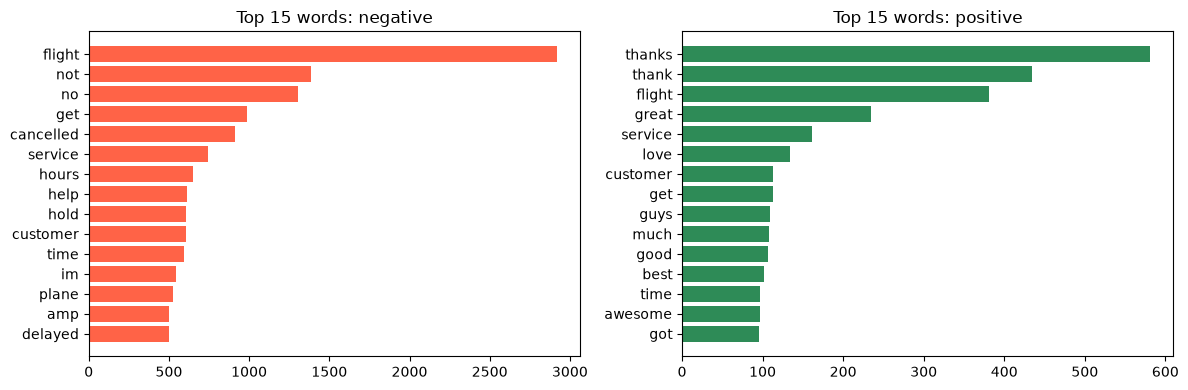

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, lab, color in zip(axes, ['negative', 'positive'], ['tomato', 'seagreen']):
    words, freq = zip(*class_counters[lab].most_common(15))
    ax.barh(words[::-1], freq[::-1], color=color)
    ax.set_title(f'Top 15 words: {lab}')
plt.tight_layout()
plt.show()

**Interpretation:** negative tweets are full of problem words (delay, cancelled, hours, bag), while positive tweets are dominated by thanks, great and good. Many words appear only once, which are mostly typos and rare names. This tells me that `min_df=2` will remove a lot of noise from the vocabulary, and `max_features` can be limited without losing the useful words.

## Task 3: Different NLP Approaches - Heuristic & API-based
**Objective:** build a rule-based and a ready-made sentiment method and measure both on the same test set.
**Expected output:** lexicon function, VADER scores, evaluation table, confusion matrices and failure cases.

### 3.1 Approaches overview
| Approach | Idea | Advantage | Disadvantage |
|---|---|---|---|
| Heuristic | Hand-written rules and word lists | Simple, fast, easy to explain, no data needed | Needs manual work, cannot cover all words, weak on sarcasm |
| API-based | Send text to a ready-made engine and get a score | No training needed, quick to start | General-purpose, not aware of domain words; cloud versions need account, key and billing; privacy concerns |
| ML-based | Learn patterns from labelled data | Learns domain words, usually the most accurate | Needs labelled data and training |

**When to choose:** heuristic for a quick prototype with no data; API-based when the budget allows and the data is not private and general; ML-based when labelled data exists and accuracy matters, or when data must stay inside the company.

### 3.2 Heuristic approach

In [26]:
positive_words = set(['amazing', 'appreciate', 'appreciated', 'awesome', 'best', 'comfortable', 'early', 'easy', 'enjoy', 'enjoyed', 'excellent', 'fantastic', 'fast', 'friendly', 'good', 'great', 'happy', 'helpful', 'impressed', 'kudos', 'love', 'loved', 'nice', 'outstanding', 'perfect', 'pleasant', 'polite', 'professional', 'quick', 'resolved', 'safe', 'smooth', 'thank', 'thanks', 'welcome', 'wonderful'])
negative_words = set(['angry', 'awful', 'bad', 'broken', 'canceled', 'cancellation', 'cancelled', 'complaint', 'damaged', 'delay', 'delayed', 'delays', 'disappointed', 'disappointing', 'disgusting', 'failed', 'hate', 'hold', 'horrible', 'late', 'lost', 'missed', 'nightmare', 'overbooked', 'poor', 'refund', 'ridiculous', 'rude', 'slow', 'stuck', 'terrible', 'unacceptable', 'unhelpful', 'useless', 'waiting', 'worse', 'worst'])
print(len(positive_words), 'positive words,', len(negative_words), 'negative words')

36 positive words, 37 negative words


In [27]:
def heuristic_score(text):
    words = clean_text(text).split()
    score = 0
    for i, w in enumerate(words):
        if w in positive_words:
            value = 1
        elif w in negative_words:
            value = -1
        else:
            continue
        if any(p in negation_words for p in words[max(0, i - 2):i]):
            value = -value
        score += value
    return score


def heuristic_sentiment(text):
    score = heuristic_score(text)
    if score > 0:
        return 'positive'
    if score < 0:
        return 'negative'
    return 'neutral'

In [28]:
tests = [
    'Thanks, great service from the crew!',
    'My flight was delayed and my bag is lost',
    'not happy with the delay',
    'The flight was not bad at all',
    'What time does gate 5 open?',
]
for t in tests:
    print(heuristic_score(t), heuristic_sentiment(t), '|', t)

2 positive | Thanks, great service from the crew!
-2 negative | My flight was delayed and my bag is lost
-2 negative | not happy with the delay
1 positive | The flight was not bad at all
0 neutral | What time does gate 5 open?


### 3.3 API-based approach (VADER)

In [29]:
from nltk.sentiment import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

def vader_sentiment(text):
    compound = sia.polarity_scores(text)['compound']
    if compound >= 0.05:
        return 'positive'
    if compound <= -0.05:
        return 'negative'
    return 'neutral'

print(vader_sentiment('Thanks, great service!'), vader_sentiment('Worst flight ever'))

positive negative


Cloud services such as **Google Cloud Natural Language, AWS Comprehend and Azure Text Analytics** work in the same way: we send text and receive JSON with a sentiment score. They need an account, an API key and billing, so they are only described here. VADER is a local, lexicon-based engine made for social-media text, so it works the same way without any key.

### 3.4 Evaluate both on the same test set

In [30]:
from sklearn.model_selection import train_test_split

X = df['clean_text']
y = df['airline_sentiment']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_test.shape)

(11561,) (2891,)


In [31]:
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay
from sklearn.metrics import precision_recall_fscore_support

all_rows = []

def evaluate(y_true, y_pred, approach, features='-', classifier='-'):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, average='macro')
    prec, rec, _, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels)
    print(approach, '| accuracy', round(acc, 3), '| macro-F1', round(f1, 3))
    print(classification_report(y_true, y_pred, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, labels=labels, cmap='Blues')
    plt.title(approach)
    plt.show()
    return {'Approach': approach, 'Features': features, 'Classifier': classifier, 'Accuracy': acc, 'Macro-F1': f1,
            'Precision (negative)': dict(zip(labels, prec))['negative'],
            'Recall (positive)': dict(zip(labels, rec))['positive']}

Heuristic | accuracy 0.527 | macro-F1 0.544
              precision    recall  f1-score   support

    negative      0.937     0.402     0.563      1818
     neutral      0.306     0.796     0.442       613
    positive      0.593     0.663     0.626       460

    accuracy                          0.527      2891
   macro avg      0.612     0.620     0.544      2891
weighted avg      0.749     0.527     0.547      2891



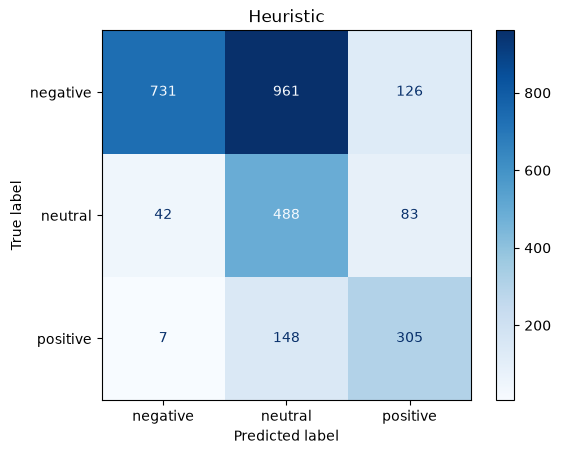

In [32]:
test_raw = df.loc[X_test.index, 'text']

heur_pred = test_raw.apply(heuristic_sentiment)
all_rows.append(evaluate(y_test, heur_pred, 'Heuristic', 'Lexicon', 'Rules'))

API-based | accuracy 0.543 | macro-F1 0.509
              precision    recall  f1-score   support

    negative      0.899     0.502     0.644      1818
     neutral      0.384     0.432     0.406       613
    positive      0.331     0.852     0.477       460

    accuracy                          0.543      2891
   macro avg      0.538     0.595     0.509      2891
weighted avg      0.699     0.543     0.567      2891



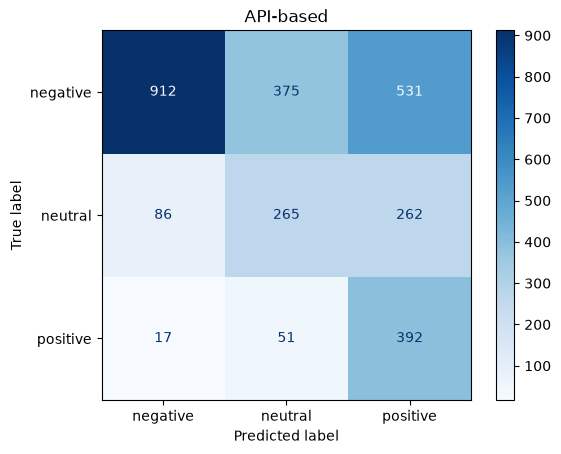

In [33]:
vader_pred = test_raw.apply(vader_sentiment)
all_rows.append(evaluate(y_test, vader_pred, 'API-based', 'VADER', 'Lexicon engine'))

In [34]:
pd.DataFrame(all_rows)[['Approach', 'Accuracy', 'Macro-F1', 'Precision (negative)', 'Recall (positive)']].round(3)

,Approach,Accuracy,Macro-F1,Precision (negative),Recall (positive)
0,Heuristic,0.527,0.544,0.937,0.663
1,API-based,0.543,0.509,0.899,0.852


### 3.5 Where do rules and ready-made tools fail?

In [35]:
wrong_heur = test_raw[(heur_pred != y_test)].head(2)
for idx, t in wrong_heur.items():
    print('HEURISTIC | true:', y_test[idx], '| predicted:', heur_pred[idx], '| score:', heuristic_score(t))
    print(t)
    print()

HEURISTIC | true: negative | predicted: neutral | score: 0
@AmericanAir Finally got a call from AA, but it was an automated voice that hung up on me! I called back &amp; it says it'll be 2 more hours.

HEURISTIC | true: negative | predicted: neutral | score: 0
@USAirways Really a letter that says you will discuss serving drunks more drinks that doesn't help the current situation



In [36]:
wrong_vader = test_raw[(vader_pred != y_test)].head(2)
for idx, t in wrong_vader.items():
    print('VADER | true:', y_test[idx], '| predicted:', vader_pred[idx], '| compound:', sia.polarity_scores(t)['compound'])
    print(t)
    print()

VADER | true: negative | predicted: neutral | compound: 0.0
@AmericanAir Finally got a call from AA, but it was an automated voice that hung up on me! I called back &amp; it says it'll be 2 more hours.

VADER | true: negative | predicted: positive | compound: 0.3818
@united JH: going to process my refund for wifi. its asking for a receipt #? I never received an email- you guys just whacked my credit card



**Typical causes:** the heuristic misses any word that is not in my small list and cannot understand sarcasm; VADER is general-purpose, so airline words like "delayed" or "hold" are not strongly negative for it, and many neutral tweets (questions, news) get a positive or negative score by chance. A model trained on labelled airline tweets can learn these domain words, which is why Tasks 4 to 6 are needed.

## Task 4: Feature Extraction - Bag-of-Words, TF-IDF & N-Grams
**Objective:** convert text into numbers.
**Expected output:** BoW and TF-IDF made by hand and with sklearn, n-gram comparison and a feature-size experiment.

### 4.1 Why feature extraction
Models work with numbers, not text, so every document must become a numeric vector.

| Method | Captures | Ignores | Vector size | Sparsity | Typical weakness |
|---|---|---|---|---|---|
| Bag-of-Words | How many times each word appears | Word order, meaning | Vocabulary size | Very sparse | Common words dominate; "good, not bad" = "bad, not good" |
| TF-IDF | Word count weighted by how rare the word is across documents | Word order, meaning | Vocabulary size | Very sparse | Still no meaning or order |
| N-grams | Short word sequences (e.g. "not happy") | Long-range context | Grows very fast with n | Extremely sparse | Vocabulary explosion |

### 4.2 Bag-of-Words by hand and with sklearn

In [37]:
sentences = [
    'the flight was good',
    'the flight was not good',
    'the crew was rude and the flight was late',
    'the crew was friendly not rude',
]

In [38]:
manual_counts = [Counter(s.split()) for s in sentences]
vocab = sorted(set(w for s in sentences for w in s.split()))

bow_manual = pd.DataFrame([[c[w] for w in vocab] for c in manual_counts], columns=vocab)
bow_manual

,and,crew,flight,friendly,good,late,not,rude,the,was
0,0,0,1,0,1,0,0,0,1,1
1,0,0,1,0,1,0,1,0,1,1
2,1,1,1,0,0,1,0,1,2,2
3,0,1,0,1,0,0,1,1,1,1


In [39]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer()
bow_sklearn = pd.DataFrame(cv.fit_transform(sentences).toarray(), columns=cv.get_feature_names_out())
bow_sklearn

,and,crew,flight,friendly,good,late,not,rude,the,was
0,0,0,1,0,1,0,0,0,1,1
1,0,0,1,0,1,0,1,0,1,1
2,1,1,1,0,0,1,0,1,2,2
3,0,1,0,1,0,0,1,1,1,1


In [40]:
print('Manual and sklearn BoW match:', bow_manual.equals(bow_sklearn))

Manual and sklearn BoW match: True


**Why "the movie was good, not bad" and "the movie was bad, not good" are hard to separate:** both contain the same words with the same counts, and BoW ignores order, so their vectors are identical.

### 4.3 TF-IDF by hand

In [41]:
N = len(sentences)
tf = bow_manual.values
df_count = (tf > 0).sum(axis=0)
idf = np.log(N / df_count) + 1

tfidf_manual = pd.DataFrame(tf * idf, columns=vocab)
tfidf_manual.round(3)

,and,crew,flight,friendly,good,late,not,rude,the,was
0,0.000,0.000,1.288,0.000,1.693,0.000,0.000,0.000,1.0,1.0
1,0.000,0.000,1.288,0.000,1.693,0.000,1.693,0.000,1.0,1.0
2,2.386,1.693,1.288,0.000,0.000,2.386,0.000,1.693,2.0,2.0
3,0.000,1.693,0.000,2.386,0.000,0.000,1.693,1.693,1.0,1.0


In [42]:
from sklearn.feature_extraction.text import TfidfVectorizer

tv = TfidfVectorizer(smooth_idf=False, norm=None)
tfidf_sklearn = tv.fit_transform(sentences).toarray()
print('Manual TF-IDF matches sklearn:', np.allclose(tfidf_manual.values, tfidf_sklearn))

Manual TF-IDF matches sklearn: True


In [43]:
tv_default = TfidfVectorizer()
default_out = tv_default.fit_transform(sentences).toarray()
print('Default matches manual:', np.allclose(tfidf_manual.values, default_out))
print('Row length (L2 norm) in default version:', np.linalg.norm(default_out, axis=1).round(2))

Default matches manual: False
Row length (L2 norm) in default version: [1. 1. 1. 1.]


**Two differences in the default `TfidfVectorizer()`:** (1) *smoothing*: idf = ln((1+N)/(1+df)) + 1, which avoids division by zero; (2) *L2 normalisation*: every row is scaled to length 1, so long and short documents are comparable.

**Why a word in every document gets a low weight:** its idf = ln(N/N) + 1 = 1 is the lowest possible, because a word that appears everywhere cannot help to tell documents apart.

### 4.4 BoW and TF-IDF on the airline tweets

In [44]:
def describe(X, name):
    total = X.shape[0] * X.shape[1]
    print(name, '| shape', X.shape, '| vocabulary', X.shape[1], '| non-zero', X.nnz,
          '| sparsity %.2f%%' % (100 * (1 - X.nnz / total)))

In [45]:
cv_tweets = CountVectorizer()
X_train_bow = cv_tweets.fit_transform(X_train)
X_test_bow = cv_tweets.transform(X_test)
describe(X_train_bow, 'BoW train')
describe(X_test_bow, 'BoW test')

BoW train | shape (11561, 10017) | vocabulary 10017 | non-zero 167425 | sparsity 99.86%
BoW test | shape (2891, 10017) | vocabulary 10017 | non-zero 40577 | sparsity 99.86%


In [46]:
tv_tweets = TfidfVectorizer()
X_train_tfidf = tv_tweets.fit_transform(X_train)
X_test_tfidf = tv_tweets.transform(X_test)
describe(X_train_tfidf, 'TF-IDF train')
describe(X_test_tfidf, 'TF-IDF test')

TF-IDF train | shape (11561, 10017) | vocabulary 10017 | non-zero 167425 | sparsity 99.86%
TF-IDF test | shape (2891, 10017) | vocabulary 10017 | non-zero 40577 | sparsity 99.86%


In [47]:
for params in [{'min_df': 2}, {'max_features': 5000}]:
    X_tmp = TfidfVectorizer(**params).fit_transform(X_train)
    print(params, '-> vocabulary size', X_tmp.shape[1])

{'min_df': 2} -> vocabulary size 4974
{'max_features': 5000} -> vocabulary size 5000


**Why fit on training data only:** the test set must act like new, unseen tweets. If the vectoriser sees test tweets, its vocabulary and idf values carry information from the test set into training (data leakage), and the test score becomes too optimistic.

### 4.5 N-Grams

In [48]:
ngram_stats = []

for ngram in [(1, 1), (1, 2), (1, 3)]:
    X_tmp = TfidfVectorizer(ngram_range=ngram).fit_transform(X_train)
    ngram_stats.append((str(ngram), X_tmp.shape[1], X_tmp.data.nbytes))
    print(ngram, '-> vocabulary size', X_tmp.shape[1])

(1, 1) -> vocabulary size 10017
(1, 2) -> vocabulary size 86962
(1, 3) -> vocabulary size 214767


In [49]:
tv_bi = TfidfVectorizer(ngram_range=(1, 2))
X_train_bi = tv_bi.fit_transform(X_train)
features = tv_bi.get_feature_names_out()
is_bigram = np.array([' ' in f for f in features])

for lab in ['negative', 'positive']:
    mean_weights = np.asarray(X_train_bi[(y_train == lab).values].mean(axis=0)).ravel()
    top = np.argsort(mean_weights * is_bigram)[::-1][:15]
    print(lab, '->', [features[i] for i in top])
    print()

negative -> ['on hold', 'customer service', 'cancelled flightled', 'on the', 'my flight', 'to get', 'hold for', 'trying to', 'to be', 'an hour', 'this is', 'been on', 'late flight', 'in the', 'you guys']

positive -> ['thank you', 'thanks for', 'for the', 'you for', 'you guys', 'so much', 'the best', 'customer service', 'for your', 'in the', 'to the', 'thanks so', 'on the', 'love you', 'made it']



**What bigrams add:** "not happy" is negative even though "happy" alone is positive, and "customer service" is a single idea that its two words do not show separately. **Cost of larger n:** the vocabulary grows very fast (see the sizes above), most n-grams appear only once, and the matrix becomes sparser and heavier.

### 4.6 Feature-size experiment

In [50]:
feature_stats = []

for n in [1000, 3000, 5000, 10000]:
    X_tmp = TfidfVectorizer(max_features=n).fit_transform(X_train)
    feature_stats.append((str(n), X_tmp.shape[1], X_tmp.data.nbytes))

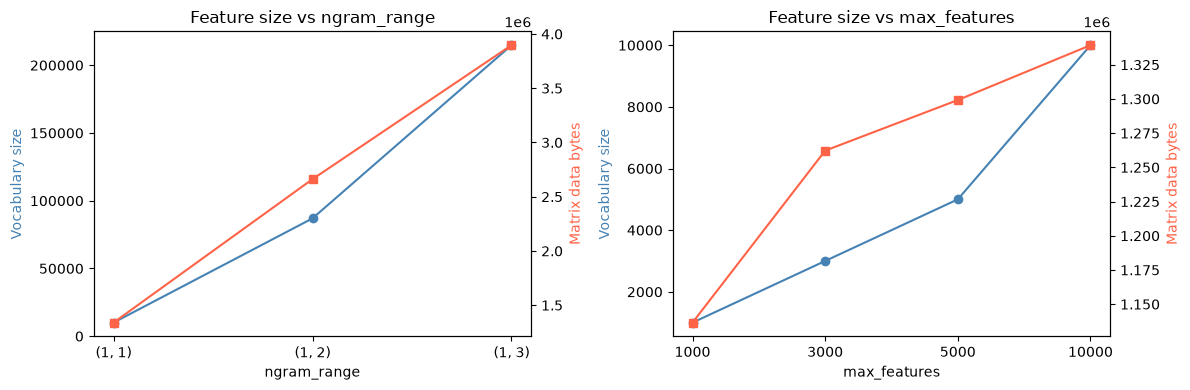

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, stats, title in zip(axes, [ngram_stats, feature_stats], ['ngram_range', 'max_features']):
    names, vocab_sizes, memory = zip(*stats)
    ax.plot(names, vocab_sizes, marker='o', color='steelblue')
    ax.set_xlabel(title)
    ax.set_ylabel('Vocabulary size', color='steelblue')
    ax2 = ax.twinx()
    ax2.plot(names, memory, marker='s', color='tomato')
    ax2.set_ylabel('Matrix data bytes', color='tomato')
    ax.set_title(f'Feature size vs {title}')
plt.tight_layout()
plt.show()

**Interpretation:** the vocabulary and memory grow quickly with n-grams, while `max_features` gives a controlled size. A sensible setting is bigrams with `min_df=2`: it keeps useful phrases like "not happy" but removes rare noise. The final choice should be made by validation score, not by size alone.

## Task 5: Word Embeddings, Word2Vec - CBoW & Skip-gram
**Objective:** represent words as dense vectors that capture meaning.
**Expected output:** two trained Word2Vec models, similar-word table, PCA plot and document vectors.

### 5.1 Word embeddings
BoW and TF-IDF give every word its own column, so they are sparse and treat "late" and "delayed" as completely unrelated. A word embedding places each word as a short dense vector (for example 100 numbers), and words used in similar contexts get similar vectors. The idea: *a word is known by the company it keeps.*

### 5.2 CBoW vs Skip-gram
| | CBoW | Skip-gram |
|---|---|---|
| Input | Context words | Centre word |
| Output | Centre word | Context words |
| Training speed | Faster | Slower |
| Rare words | Weaker | Better |
| Frequent words | Good | Good |
| Prefer when | Large corpus, speed matters | Small corpus, rare words matter |

Sentence: **"the flight was delayed again"**, window = 2, centre word = `delayed`

- CBoW (context -> centre): (the, flight, was, again) -> delayed
- Skip-gram (centre -> context): delayed -> the, delayed -> flight, delayed -> was, delayed -> again

### 5.3 Train both models

In [52]:
from gensim.models import Word2Vec
import time

train_tokens = [t.split() for t in X_train]
print('Training sentences:', len(train_tokens))

Training sentences: 11561


In [53]:
start = time.time()
cbow = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=3, sg=0, epochs=20, seed=42, workers=1)
print('CBoW | vocabulary', len(cbow.wv), '| vector shape', cbow.wv['flight'].shape, '| time %.1fs' % (time.time() - start))

CBoW | vocabulary 3700 | vector shape (100,) | time 5.0s


In [54]:
start = time.time()
skip = Word2Vec(sentences=train_tokens, vector_size=100, window=5, min_count=3, sg=1, epochs=20, seed=42, workers=1)
print('Skip-gram | vocabulary', len(skip.wv), '| vector shape', skip.wv['flight'].shape, '| time %.1fs' % (time.time() - start))

Skip-gram | vocabulary 3700 | vector shape (100,) | time 14.3s


### 5.4 Explore the vectors

In [55]:
query_words = ['delayed', 'flight', 'thanks', 'rude', 'luggage', 'great']
rows = []

for w in query_words:
    row = {'Word': w}
    for name, model in [('CBoW', cbow), ('Skip-gram', skip)]:
        row[name] = ', '.join(x for x, _ in model.wv.most_similar(w, topn=5)) if w in model.wv else 'not in vocabulary'
    rows.append(row)

pd.DataFrame(rows)

,Word,CBoW,Skip-gram
0,delayed,"late, scheduled, leaving, delay, original","inbound, causing, glitch, departed, redirected"
1,flight,"flt, connection, trip, flightst, flights","previously, nite, discovered, flts, woo"
2,thanks,"thx, thank, sending, quick, shoutout","thx, thank, thanx, prompt, thnx"
3,rude,"helpful, unhelpful, friendly, attitude, staff","unprofessional, fabulous, karen, providence, named"
4,luggage,"bag, bags, wallet, baggage, husband","bag, bags, carousel, suitcase, baggage"
5,great,"wonderful, excellent, awesome, outstanding, btw","wonderful, awesome, outstanding, mardigras, recovery"


In [56]:
pairs = [('delayed', 'late'), ('good', 'great'), ('flight', 'banana')]

for a, b in pairs:
    for name, model in [('CBoW', cbow), ('Skip-gram', skip)]:
        if a in model.wv and b in model.wv:
            print(name, a, '-', b, round(float(model.wv.similarity(a, b)), 3))
        else:
            print(name, a, '-', b, 'one word is not in the vocabulary')

CBoW delayed - late 0.64
Skip-gram delayed - late 0.563
CBoW good - great 0.418
Skip-gram good - great 0.4
CBoW flight - banana one word is not in the vocabulary
Skip-gram flight - banana one word is not in the vocabulary


**Interpretation:** many neighbours are sensible (related complaint words and thank-you words), but some are odd. This corpus is small (a few hundred thousand tokens), so the vectors are noisier than ones trained on huge corpora such as news or Wikipedia. Skip-gram is generally steadier on rare words in a small corpus, so I use it for the document vectors below; confirm this against the table above.

### 5.5 Visualise embeddings

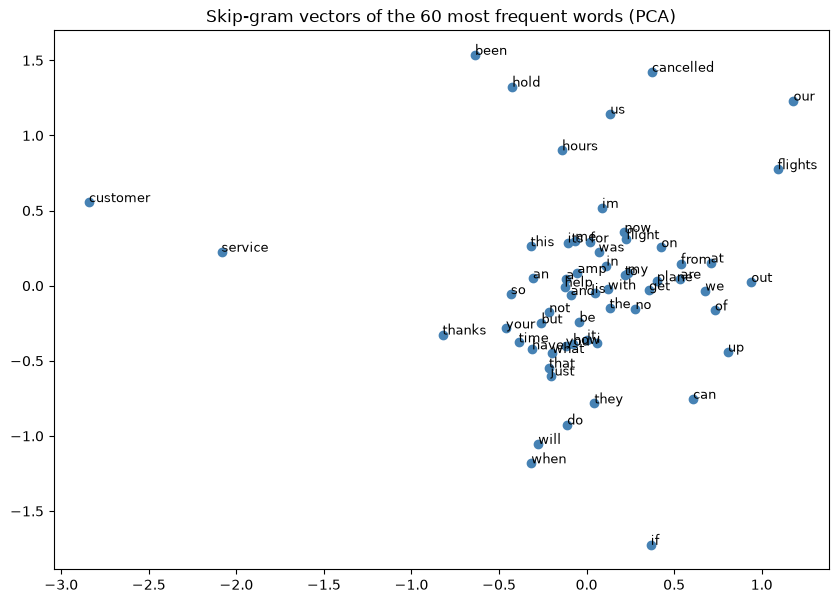

In [57]:
from sklearn.decomposition import PCA

top_words = skip.wv.index_to_key[:60]
points = PCA(n_components=2, random_state=42).fit_transform(skip.wv[top_words])

plt.figure(figsize=(10, 7))
plt.scatter(points[:, 0], points[:, 1], color='steelblue')
for word, (px, py) in zip(top_words, points):
    plt.annotate(word, (px, py), fontsize=9)
plt.title('Skip-gram vectors of the 60 most frequent words (PCA)')
plt.show()

**Description:** words with similar roles sit close together, for example thank-you words, complaint words (delay, cancelled, hours) and flight-related nouns. Because PCA squeezes 100 dimensions into 2, some clusters overlap.

### 5.6 From word vectors to document vectors

In [58]:
def doc_vector(tokens, model):
    vectors = [model.wv[w] for w in tokens if w in model.wv]
    if len(vectors) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis=0)

In [59]:
w2v_model = skip

X_train_w2v = np.array([doc_vector(t.split(), w2v_model) for t in X_train])
X_test_w2v = np.array([doc_vector(t.split(), w2v_model) for t in X_test])
print(X_train_w2v.shape, X_test_w2v.shape)

(11561, 100) (2891, 100)


**What is lost by averaging:** word order, and the strength of single important words (one strong word like "rude" is blended with all the other words), so a negation can be hidden.

## Task 6: Text Classification Pipeline & Approach Comparison
**Objective:** train classifiers on the different features and compare all approaches fairly.
**Expected output:** baseline pipeline, results table, bar chart, cross-validation, error analysis, saved model.

### 6.1 Text classification and the pipeline
Text classification means giving **one label to a whole document**; here, one sentiment per tweet. My pipeline: raw tweet -> cleaning (`clean_text`) -> features (TF-IDF) -> classifier (Logistic Regression) -> predicted sentiment -> evaluation (macro-F1).

A scikit-learn `Pipeline` joins the vectoriser and classifier into one object. When we call `fit`, the vectoriser learns only from training data, and cross-validation refits it inside every fold, so there is no leakage. For deployment, one saved file handles both steps.

### 6.2 Baseline pipeline

In [60]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

Baseline TF-IDF (1,2) + LR | accuracy 0.784 | macro-F1 0.731
              precision    recall  f1-score   support

    negative      0.881     0.845     0.863      1818
     neutral      0.584     0.644     0.613       613
    positive      0.710     0.728     0.719       460

    accuracy                          0.784      2891
   macro avg      0.725     0.739     0.731      2891
weighted avg      0.791     0.784     0.787      2891



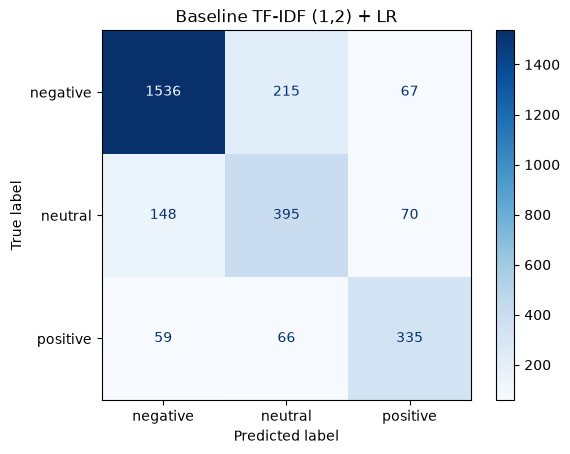

In [61]:
baseline_row = evaluate(y_test, baseline_pred, 'Baseline TF-IDF (1,2) + LR')

**Why `class_weight='balanced'`:** negative tweets are the majority, so a normal model favours them and ignores the small positive class. Balanced weights give rare classes more importance, which helps macro-F1.

### 6.3 Compare feature approaches

In [62]:
from sklearn.naive_bayes import MultinomialNB

def lr():
    return LogisticRegression(max_iter=1000, class_weight='balanced')

combos = [
    ('BoW', 'BoW', 'Multinomial NB', Pipeline([('vec', CountVectorizer()), ('clf', MultinomialNB())])),
    ('BoW', 'BoW', 'Logistic Regression', Pipeline([('vec', CountVectorizer()), ('clf', lr())])),
    ('TF-IDF', 'TF-IDF unigrams', 'Logistic Regression', Pipeline([('vec', TfidfVectorizer()), ('clf', lr())])),
    ('N-gram', 'TF-IDF uni+bigrams', 'Logistic Regression', Pipeline([('vec', TfidfVectorizer(ngram_range=(1, 2), min_df=2)), ('clf', lr())])),
]

In [63]:
fitted = {}
ml_rows = []

for approach, features_name, clf_name, pipe in combos:
    start = time.time()
    pipe.fit(X_train, y_train)
    seconds = time.time() - start
    pred = pipe.predict(X_test)
    row = {'Approach': approach, 'Features': features_name, 'Classifier': clf_name,
           'Accuracy': accuracy_score(y_test, pred), 'Macro-F1': f1_score(y_test, pred, average='macro')}
    prec, rec, _, _ = precision_recall_fscore_support(y_test, pred, labels=labels)
    row['Precision (negative)'] = dict(zip(labels, prec))['negative']
    row['Recall (positive)'] = dict(zip(labels, rec))['positive']
    row['Training time (s)'] = seconds
    ml_rows.append(row)
    fitted[(features_name, clf_name)] = pipe

In [64]:
start = time.time()
w2v_clf = lr().fit(X_train_w2v, y_train)
seconds = time.time() - start
pred = w2v_clf.predict(X_test_w2v)
prec, rec, _, _ = precision_recall_fscore_support(y_test, pred, labels=labels)

ml_rows.append({'Approach': 'Word2Vec', 'Features': 'Averaged Skip-gram vectors', 'Classifier': 'Logistic Regression',
                'Accuracy': accuracy_score(y_test, pred), 'Macro-F1': f1_score(y_test, pred, average='macro'),
                'Precision (negative)': dict(zip(labels, prec))['negative'],
                'Recall (positive)': dict(zip(labels, rec))['positive'], 'Training time (s)': seconds})

In [65]:
results = pd.DataFrame(ml_rows)
results.round(3).style.highlight_max(subset=['Macro-F1'], color='lightgreen')

,Approach,Features,Classifier,Accuracy,Macro-F1,Precision (negative),Recall (positive),Training time (s)
0,BoW,BoW,Multinomial NB,0.761000,0.657000,0.771000,0.546000,0.253000
1,BoW,BoW,Logistic Regression,0.768000,0.719000,0.891000,0.722000,1.132000
2,TF-IDF,TF-IDF unigrams,Logistic Regression,0.767000,0.717000,0.887000,0.728000,0.991000
3,N-gram,TF-IDF uni+bigrams,Logistic Regression,0.784000,0.731000,0.881000,0.728000,1.160000
4,Word2Vec,Averaged Skip-gram vectors,Logistic Regression,0.719000,0.669000,0.862000,0.689000,0.502000


The test set was used only for reporting; no setting was tuned on it.

### 6.4 Compare all three NLP approaches

In [66]:
all_rows_df = pd.concat([pd.DataFrame(all_rows), results], ignore_index=True)
best_per_approach = all_rows_df.groupby('Approach')['Macro-F1'].max().reindex(
    ['Heuristic', 'API-based', 'BoW', 'TF-IDF', 'N-gram', 'Word2Vec'])
best_per_approach.round(3)

Approach
Heuristic    0.544
API-based    0.509
BoW          0.719
TF-IDF       0.717
N-gram       0.731
Word2Vec     0.669
Name: Macro-F1, dtype: float64

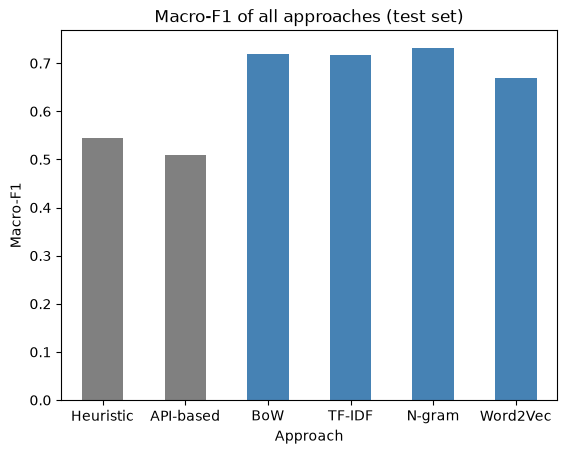

Ranking: N-gram (0.731), BoW (0.719), TF-IDF (0.717), Word2Vec (0.669), Heuristic (0.544), API-based (0.509)


In [67]:
best_per_approach.plot(kind='bar', color=['grey', 'grey', 'steelblue', 'steelblue', 'steelblue', 'steelblue'])
plt.ylabel('Macro-F1')
plt.title('Macro-F1 of all approaches (test set)')
plt.xticks(rotation=0)
plt.show()

ranking = best_per_approach.sort_values(ascending=False)
print('Ranking:', ', '.join(f'{k} ({v:.3f})' for k, v in ranking.items()))

**Reading the result:** the ranking printed above is based on measured macro-F1. Approaches trained on labelled airline tweets can learn domain words, while the heuristic and the API-based tools use fixed word lists, so I expect the trained models to rank higher, but the numbers decide. I deploy the best **scikit-learn Pipeline** (not Word2Vec, which needs the Word2Vec model too), because it saves into a single file and loads quickly in the app.

### 6.5 Cross-validation of the best pipeline

In [68]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

ml_only = results[results['Approach'] != 'Word2Vec']
best_row = ml_only.loc[ml_only['Macro-F1'].idxmax()]
best_pipeline = fitted[(best_row['Features'], best_row['Classifier'])]
print('Best pipeline:', best_row['Features'], '+', best_row['Classifier'])

Best pipeline: TF-IDF uni+bigrams + Logistic Regression


In [69]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(best_pipeline, X_train, y_train, cv=cv, scoring='f1_macro')

print('CV macro-F1 per fold:', cv_scores.round(3))
print('Mean: %.3f | Std: %.3f' % (cv_scores.mean(), cv_scores.std()))
print('Test macro-F1: %.3f' % best_row['Macro-F1'])

CV macro-F1 per fold: [0.73  0.739 0.748 0.755 0.737]
Mean: 0.742 | Std: 0.009
Test macro-F1: 0.731


**Interpretation:** if the cross-validation mean and the test score are close, the model is stable. A large gap would suggest overfitting, a lucky or unlucky split, or leakage.

### 6.6 Error analysis

In [70]:
best_pred = best_pipeline.predict(X_test)
best_proba = best_pipeline.predict_proba(X_test)

wrong = np.where(best_pred != y_test.values)[0]
rng = np.random.RandomState(42)
chosen = rng.choice(wrong, size=min(8, len(wrong)), replace=False)

pd.DataFrame({
    'Tweet': test_raw.values[chosen],
    'True': y_test.values[chosen],
    'Predicted': best_pred[chosen],
    'Probability': best_proba[chosen].max(axis=1).round(2),
})

,Tweet,True,Predicted,Probability
0,@USAirways How can I change without penalty and not have to call customer service,neutral,negative,0.84
1,@USAirways @AmericanAir thought u merged but #USAirways sucks #worstever http://t.co/myNZitCovn,negative,neutral,0.47
2,@SouthwestAir thanks for the response - flight time has passed - rebooked now,negative,positive,0.83
3,@united mobile apps need construction from the ground up for each OS category. It's expensive to get right .,negative,neutral,0.57
4,@USAirways power trip. I felt completely threatened and unsafe and I am so angry. Derrick Bussey. DCA. Would like to reiterate that I was,negative,positive,0.48
5,@united as a freq flyer it makes me sad to see cust needing assistance treated so poorly. #ServiceFail,negative,neutral,0.39
6,"@united Fair enough. I don't usually rant, but it's good to know someone's listening. :)",positive,neutral,0.43
7,@USAirways thank you for putting me on a flight that will be leaving Late Flightr than the original flight I was booked on.,negative,positive,0.43


**Error patterns:** (1) neutral tweets confused with negative, because neutral tweets often mention a problem as a question; (2) sarcasm, where positive words describe a bad experience; (3) very short tweets with almost no information; (4) mixed sentiment (thanks plus complaint).

**Two improvement ideas inside this practical:** add trigrams or tune `min_df`, and add POS-filtered features (Task 7.5).

### 6.7 Save the final pipeline

In [71]:
import joblib
import sklearn

joblib.dump(best_pipeline, 'sentiment_model.joblib')
print('scikit-learn version used:', sklearn.__version__)

scikit-learn version used: 1.5.2


In [72]:
loaded = joblib.load('sentiment_model.joblib')

new_sentences = ['Thanks to the crew, the flight was smooth',
                 'My bag is lost and nobody helps',
                 'What is the baggage allowance?']
print(loaded.predict([clean_text(s) for s in new_sentences]))

['positive' 'negative' 'neutral']


## Task 7: POS Tagging
**Objective:** understand how words are tagged by grammar role and check if it helps sentiment.
**Expected output:** tagged tweets, POS distribution by sentiment, and a POS-filtered pipeline.

### 7.1 What is POS tagging
Part-of-speech (POS) tagging gives each word its grammar role.

| Part of speech | Penn Treebank tag | Example |
|---|---|---|
| Noun | NN | flight |
| Verb | VB | cancel |
| Adjective | JJ | rude |
| Adverb | RB | never |
| Pronoun | PRP | they |
| Preposition | IN | at |

It is useful for information extraction, grammar checking, building better features and solving ambiguity.

### 7.2 How POS tagging works
1. **Rule-based tagger:** uses a dictionary and hand-written rules (for example, a word ending in "-ly" is probably an adverb).
2. **Statistical tagger:** learns from a tagged corpus the probability of a tag given the word and the neighbouring tags (Hidden Markov Models, averaged perceptron).
3. **Context solves ambiguity:** the same word can get different tags depending on the sentence.

NLTK's `pos_tag` uses a trained **averaged-perceptron** model, trained on news-style text.

In [73]:
ambiguity = ['I will book a ticket', 'I read a good book', 'We walk in the park', 'You cannot park here']

for s in ambiguity:
    print(nltk.pos_tag(word_tokenize(s)))

[('I', 'PRP'), ('will', 'MD'), ('book', 'NN'), ('a', 'DT'), ('ticket', 'NN')]
[('I', 'PRP'), ('read', 'VBP'), ('a', 'DT'), ('good', 'JJ'), ('book', 'NN')]
[('We', 'PRP'), ('walk', 'VBP'), ('in', 'IN'), ('the', 'DT'), ('park', 'NN')]
[('You', 'PRP'), ('can', 'MD'), ('not', 'RB'), ('park', 'VB'), ('here', 'RB')]


### 7.3 Tag sentences

In [74]:
sample_tweets = X_train.sample(5, random_state=42)
rows = []

for t in sample_tweets:
    tagged = nltk.pos_tag(t.split())
    rows.append([t, ' '.join(f'{w}/{tag}' for w, tag in tagged)])

pd.DataFrame(rows, columns=['Cleaned tweet', 'word/TAG'])

,Cleaned tweet,word/TAG
0,i have to spend more than the cost of the flight just to get a free room and transportation to and from the airport,i/NNS have/VBP to/TO spend/VB more/JJR than/IN the/DT cost/NN of/IN the/DT flight/NN just/RB to/TO get/VB a/DT free/JJ room/NN and/CC transportation/NN to/TO and/CC from/IN the/DT airport/NN
1,w edits dear your mbas need better benefits they should work for us how can we meet them,w/NN edits/NNS dear/VBP your/PRP$ mbas/NNS need/VBP better/JJR benefits/NNS they/PRP should/MD work/VB for/IN us/PRP how/WRB can/MD we/PRP meet/VB them/PRP
2,hi jh my experience with united has been entirely disgusting but yes id like assistance in getting compensated for my bag,hi/NN jh/NN my/PRP$ experience/NN with/IN united/JJ has/VBZ been/VBN entirely/RB disgusting/VBG but/CC yes/RB id/NNS like/IN assistance/NN in/IN getting/VBG compensated/VBN for/IN my/PRP$ bag/NN
3,made it never ran so fast in my life,made/VBN it/PRP never/RB ran/VBD so/RB fast/RB in/IN my/PRP$ life/NN
4,i did eventually get through but that flight cancelled flightled decided to drive but gave up holding to process refund,i/NN did/VBD eventually/RB get/VB through/IN but/CC that/IN flight/NN cancelled/VBD flightled/VBN decided/VBD to/TO drive/VB but/CC gave/VBD up/RP holding/VBG to/TO process/VB refund/NN


**Wrong tags:** look at the table for words that look wrong, for example a verb tagged as a noun, or an airline name tagged as a common word. Tweets are harder than news because the tagger was trained on formal text, while tweets use informal language, missing punctuation and lowercase text (after my cleaning, capital letters that help with names are gone).

### 7.4 POS distribution by sentiment

In [75]:
pos_sample = X_train.sample(min(2000, len(X_train)), random_state=42)
pos_tags = {idx: nltk.pos_tag(t.split()) for idx, t in pos_sample.items()}
print('Tagged tweets:', len(pos_tags))

Tagged tweets: 2000


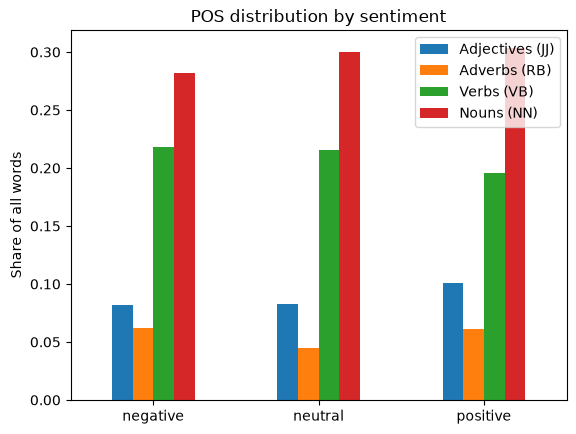

In [76]:
groups = {'Adjectives (JJ)': 'JJ', 'Adverbs (RB)': 'RB', 'Verbs (VB)': 'VB', 'Nouns (NN)': 'NN'}
dist = {}

for lab in labels:
    counts_by_group = Counter()
    total = 0
    for idx, tagged in pos_tags.items():
        if y_train[idx] != lab:
            continue
        for w, tag in tagged:
            total += 1
            for name, prefix in groups.items():
                if tag.startswith(prefix):
                    counts_by_group[name] += 1
    dist[lab] = {name: counts_by_group[name] / total for name in groups}

pd.DataFrame(dist).T.plot(kind='bar')
plt.ylabel('Share of all words')
plt.title('POS distribution by sentiment')
plt.xticks(rotation=0)
plt.show()

In [77]:
for lab in ['negative', 'positive']:
    adjectives = Counter(w for idx, tagged in pos_tags.items() if y_train[idx] == lab
                         for w, tag in tagged if tag.startswith('JJ'))
    print(lab, '->', adjectives.most_common(10))

negative -> [('i', 88), ('late', 46), ('ive', 44), ('last', 40), ('flightled', 31), ('u', 31), ('worst', 30), ('other', 24), ('due', 23), ('more', 21)]
positive -> [('great', 30), ('i', 17), ('best', 14), ('good', 10), ('last', 9), ('awesome', 8), ('new', 8), ('first', 6), ('sure', 6), ('much', 5)]


**Observation:** the share of each POS group is quite similar across the sentiments, so POS counts alone do not separate the classes much; the actual adjectives differ (for example bad, late vs great, good), which shows the words matter more than the grammar.

### 7.5 POS-filtered features

In [78]:
def pos_filter(text):
    tagged = nltk.pos_tag(text.split())
    keep = [w for w, tag in tagged if tag.startswith(('JJ', 'RB', 'VB')) or w in negation_words]
    return ' '.join(keep)

X_train_pos = X_train.apply(pos_filter)
X_test_pos = X_test.apply(pos_filter)
print(X_train_pos.head(3).tolist())

['no did said was delicious', 'ath do coordinate other', 'wow amazing great']


In [79]:
pos_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2)),
    ('clf', LogisticRegression(max_iter=1000, class_weight='balanced')),
])
pos_pipeline.fit(X_train_pos, y_train)
pos_pred = pos_pipeline.predict(X_test_pos)
pos_f1 = f1_score(y_test, pos_pred, average='macro')

comparison = pd.DataFrame({
    'Text used': ['Full cleaned text', 'POS-filtered (adj, adv, verbs, negations)'],
    'Macro-F1': [baseline_row['Macro-F1'], pos_f1],
}).round(3)
comparison

,Text used,Macro-F1
0,Full cleaned text,0.731
1,"POS-filtered (adj, adv, verbs, negations)",0.629


In [80]:
diff = pos_f1 - baseline_row['Macro-F1']
verdict = 'helped' if diff > 0.005 else 'hurt' if diff < -0.005 else 'made almost no difference'
print(f'POS filtering {verdict} (change in macro-F1: {diff:+.3f})')

POS filtering hurt (change in macro-F1: -0.102)


**Interpretation:** nouns such as *bag*, *luggage* or *refund* are strong clues for airline complaints, so removing them can hide useful information, and the tagger itself makes mistakes on tweets. The printed verdict above is the honest result.

## Task 8: Build the NLP Project and Deploy on Streamlit
**Objective:** package the project and deploy it.
**Expected output:** `nlp_utils.py`, `requirements.txt`, `app.py` (separate file) and a live Streamlit URL.

### 8.1 Plan the app
```
+------------------------------------------------------+
| Sidebar: about project, dataset link                 |
| Main:  Title                                         |
|        [ text area ]   [Example 1][Example 2][Ex. 3]  |
|        ( ) Heuristic ( ) VADER ( ) ML model           |
|        [ Predict ]                                    |
|        Result: cleaned text, coloured label,         |
|                probability bar chart (ML only),       |
|                expander with POS tags                 |
+------------------------------------------------------+
```
After pressing Predict the user sees the cleaned tweet, a green / orange / red message with the sentiment, and for the ML model a bar chart of class probabilities.

### 8.2 Project structure: shared code for notebook and app

In [81]:
import inspect

utils_code = "import re\n\n"
utils_code += f"negation_words = {sorted(negation_words)!r}\n"
utils_code += f"positive_words = {sorted(positive_words)!r}\n"
utils_code += f"negative_words = {sorted(negative_words)!r}\n\n\n"
utils_code += inspect.getsource(clean_text) + "\n\n"
utils_code += inspect.getsource(heuristic_score) + "\n\n"
utils_code += inspect.getsource(heuristic_sentiment)

with open('nlp_utils.py', 'w') as f:
    f.write(utils_code)

In [82]:
import importlib.metadata as metadata

with open('requirements.txt', 'w') as f:
    for package in ['streamlit', 'scikit-learn', 'nltk', 'pandas', 'numpy', 'joblib']:
        f.write(f'{package}=={metadata.version(package)}\n')

print(open('requirements.txt').read())

streamlit==1.66.1
scikit-learn==1.5.2
nltk==3.10.4
pandas==3.1.1
numpy==2.5.4
joblib==1.6.0



Folder for GitHub: `NLP_PR1.ipynb`, `NLP_PR1.html`, `app.py`, `nlp_utils.py`, `sentiment_model.joblib`, `requirements.txt`, `README.md`, `/screenshots`. The raw dataset is not uploaded; the README links to the Kaggle page.

`app.py` (see the separate file) imports `clean_text` and `heuristic_sentiment` from `nlp_utils.py`, so the notebook and the app use identical code.